In [1]:
import pandas as pd

# Membuat DataFrame contoh data penjualan
data = {'Penjualan': [100, 120, 130, 125, 140, 150, 500, 110, 115, 125]}
df = pd.DataFrame(data)

print(df)

   Penjualan
0        100
1        120
2        130
3        125
4        140
5        150
6        500
7        110
8        115
9        125


In [4]:
# Ukuran pemusatan data (central tendency)
# bagian ini digunakan untuk mencari nilai tengah atau reprensentatif dari data kita 
# mean (rata-rata) menggunakan .mean()
# median (nilai tengah) menggunakan .median()
# modus (nilai yang paling sering muncul) menggunakan .mode()[0]


# menghitung pemusatan data

mean_data = df['Penjualan'].mean()
median_data = df['Penjualan'].median()
modus_data = df['Penjualan'].mode()[0]

print(f"nilai rata rata:{mean_data}")
print(f"nilai tengah:{median_data}")
print(f"nilai paling sering muncul: {modus_data}")

nilai rata rata:161.5
nilai tengah:125.0
nilai paling sering muncul: 125


In [9]:
# Ukuran persebaran data (dispersion)

# bagian ini menunjukkan seberapa bervariasi atau menyebarnya data kita dari nilai pusatnya

# range (jangkauan): nilai maksimal dikurangi minimal nilai 
# varians dan standart deviasi: menggunakan .var() dan .std()
# percentile / quartile : menggunakan .quantile() misal di q1 di 25% , median q1 di 50%, q3 di 75%


#=================================

# menghitung range
range_data = df["Penjualan"].max() - df["Penjualan"].min()

# menghitung varians dan standart deviasi 
variance_data = df["Penjualan"].var()
std_data = df["Penjualan"].std()

# menghitung kuartil q1, q2/median , q3

q1 = df["Penjualan"].quantile(0.25)
q2 = df["Penjualan"].quantile(0.50)
q3 = df["Penjualan"].quantile(0.75)

print(f"range: {range_data}")
print(f"varians: {variance_data:.2f}")
print(f"standart: {std_data:.2f}")
print(f"q1 (25%): {q1}")
print(f"q2 (50%): {q2}")
print(f"q3 (75%): {q3}")


# tips cepat bisa menggunakan .describe() di pandas untuk tahu semua nya dengan lebih simple

df.describe()

range: 400
varians: 14350.28
standart: 119.79
q1 (25%): 116.25
q2 (50%): 125.0
q3 (75%): 137.5


,Penjualan
count,10.000000
mean,161.500000
std,119.792645
min,100.000000
25%,116.250000
50%,125.000000
75%,137.500000
max,500.000000


In [11]:
# deteksi anomali (outlier)

# untuk deteksi data yang menyimpang jauh (seperti angka 500) yang ada di data kita . salah satu metode paling populer adalah menggunakan (IQR)
# (Inter Quartile Range) yang menjadi dasar dari pembuatan box plot 
# 1. Hitung iqr = Q3 - Q1
# 2. batas bawah = Q1 - (1.5 / IQR)
# 3. batas atas = Q3 + (1.5 / IQR)

# ======================================

# Menghitung iqr dan batas outlier 

iqr = q3 - q1 

lower_bound = q1 - (1.5 * iqr)
upper_bound = q3 + (1.5 * iqr)

# menyaring data yang merupakan outlier 
outliers = df[(df["Penjualan"] < lower_bound) | (df["Penjualan"]> upper_bound)]

print(f"batas atas : {upper_bound}")
print(f"batas bawah: {lower_bound}")
print(f"outlier : ")
print(outliers)

batas atas : 169.375
batas bawah: 84.375
outlier : 
   Penjualan
6        500


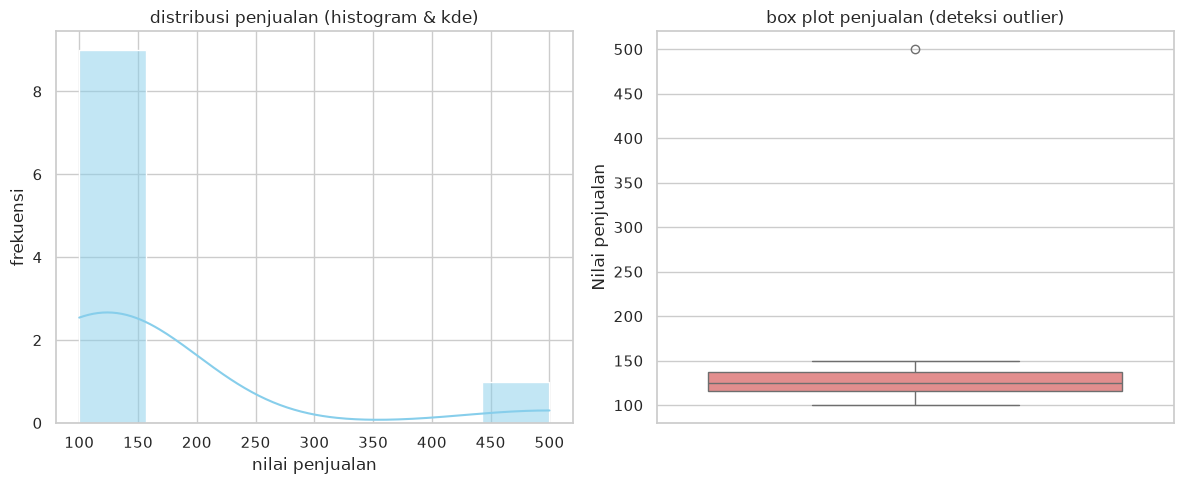

In [ ]:
import matplotlib.pyplot as plt 
import seaborn as sns 

# dataset
data = {'Penjualan': [100, 120, 130, 125, 140, 150, 500, 110, 115, 125]}
df = pd.DataFrame(data)



sns.set_theme(style='whitegrid')

# membuat figure dengan 2 subplot (histogram/kde dan box plot)
# KDE (Kernel Density Estimate) membuat garis kurva mulus yang menggambarkan bentuk distribusi data kita.
# Dari sini kita bisa melihat apakah data terkonsentrasi di sekitar rata-rata atau menyebar luas.
fig, axes = plt.subplots(1, 2,figsize=(12,5))

# 1. histogram/kde plot ( ukuran persebaran dan pemusatan secara visual)
sns.histplot(df["Penjualan"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("distribusi penjualan (histogram & kde)")
axes[0].set_xlabel("nilai penjualan")
axes[0].set_ylabel("frekuensi")


# 2. box plot (detekti outlier )

sns.boxplot(y=df["Penjualan"], ax=axes[1], color='lightcoral')
axes[1].set_title('box plot penjualan (deteksi outlier)')
axes[1].set_ylabel('Nilai penjualan')

# menampilkan plot 
plt.tight_layout()
plt.show()